# Studiul de caz 7 - Un sistem explicabil de avertizare timpurie pentru vîrfurile de preț

Energy MBA - Analiza cantitativă a piețelor de energie (EMQA) - Prof. Daniel Traian Pele

Academia de Studii Economice din București - Academia Română, Institutul de Prognoză Economică

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.join("..", "common"))   # shared helpers: cases/common/case_utils.py
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import case_utils as cu
LANG = "ro"            # "en" or "ro": language of the charts shown below (both are saved)
cu.set_lang(LANG)
T = lambda en, ro: cu.T(LANG, en, ro)
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)
%matplotlib inline

**Lucrările de referință.** Andrei, A.-V., Pele, D.-T., Cramer, A.-A., Amza, A. și Diaconu, D. (2026). Explainable AI-based early warning system for electricity
price spikes: evidence from the Romanian market. *Proceedings of the International Conference on Business Excellence (PICBE)*, 20(1), 4820-4836.
doi:10.2478/picbe-2026-0352 - și, pentru prognoza probabilistică cu păduri aleatoare, Andrei, Cepoi, Dumitrescu, Lessmann, Chiriac (Luchian), Pele și Petukhina (2026),
SSRN 6872381 (vezi studiul de caz 6).

**Conținutul notebook-ului.** (1) Definim un vîrf drept un preț orar peste percentila 90 din perioada de antrenare. (2) Construim cele două niveluri de analiză din lucrare:
un model cu arbori de decizie construiți secvențial (XGBoost, *eXtreme Gradient Boosting*), explicat cu valori SHAP (*SHapley Additive exPlanations*), și un scor de
avertizare transparent, *bazat pe praguri ale unor indicatori*, calibrat pe o perioadă de validare. (3) Transformăm *probabilitatea* prognozată a unui vîrf într-o decizie, cu ajutorul unei reguli cost-pierdere.

**Adaptarea pentru curs și extinderea perioadei.** Lucrarea folosește perioada martie-septembrie 2024 (5.000 de ore), prognozele ENTSO-E pentru ziua următoare, temperaturile, prețurile combustibililor și 70 de variabile.
Noi folosim perioada ianuarie 2023 - octombrie 2026 și aproximativ 25 de variabile. Datele cursului nu conțin prognoze pentru ziua următoare, de aceea modelul principal folosește numai informația
disponibilă la închiderea porții (ora 12:00 CET în ziua d-1): prețurile pînă în ziua d-1, precum și consumul și producția solară și eoliană realizate în ziua d-2 (ultima zi măsurată), în locul prognozelor pentru ziua d. Un al doilea clasificator, cu valorile
*efective* ale variabilelor fundamentale din ora de livrare (previziune perfectă), este raportat numai pentru comparație; nu este o prognoză.

## 1. Datele și definiția vîrfului

train      2023-01-01 - 2024-12-31:  17544 h, spike share 10.0 %
validation 2025-01-01 - 2025-06-30:   4343 h, spike share 14.2 %
test       2025-07-01 - 2026-10-31:  11711 h, spike share 23.1 %
spike threshold (P90 of training prices): 163.42 EUR/MWh (paper: P90 = 149.99 EUR/MWh in 2024)


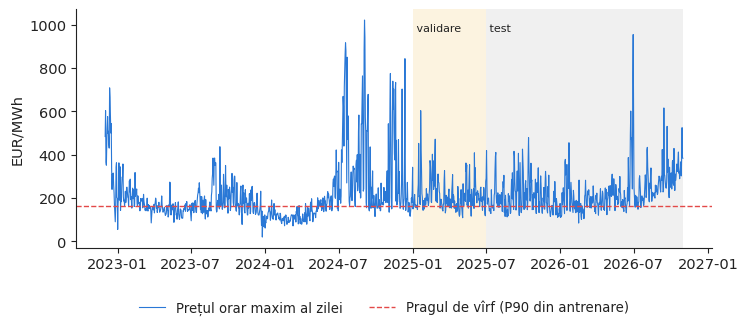

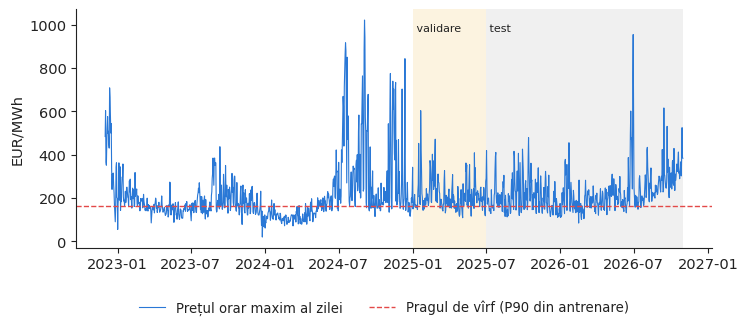

In [2]:
p = cu.prices_hourly()["RO"]; g = cu.generation_ro_hourly(); x = cu.crossborder_ro_hourly()
df = pd.concat({"price": p, "load": g["load"], "solar": g["solar"], "wind": g["wind_onshore"], "hydro": g["hydro_water_reservoir"],
                "gas": g["gas"], "net_import": x["sum"]}, axis=1).loc["2022-12-01":"2026-10-31"].dropna(subset=["price", "load", "solar", "wind"])
TRAIN, VAL, TEST = ("2023-01-01", "2024-12-31"), ("2025-01-01", "2025-06-30"), ("2025-07-01", "2026-10-31")
cet = lambda ix: ix.tz_convert("Europe/Brussels").tz_localize(None).normalize()      # CET delivery day of each hour
in_per = lambda ix, a, b: (cet(ix) >= pd.Timestamp(a)) & (cet(ix) <= pd.Timestamp(b))
thr = df.loc[in_per(df.index, *TRAIN), "price"].quantile(0.90)        # P90 of the training delivery days only
df["spike"] = (df.price > thr).astype(int)
for nm, (a, b) in zip(["train", "validation", "test"], [TRAIN, VAL, TEST]):
    s_ = df.loc[in_per(df.index, a, b)]
    print(f"{nm:10s} {a} - {b}: {len(s_):6d} h, spike share {100 * s_.spike.mean():.1f} %")
print("spike threshold (P90 of training prices): %.2f EUR/MWh (paper: P90 = 149.99 EUR/MWh in 2024)" % thr)
def fig_prices(lang):
    fig, ax = plt.subplots(figsize=(8.2, 3.1))
    d = df.price.resample("D").max()
    ax.plot(d.index, d, color=cu.PAL["RO"], lw=0.8, label=cu.T(lang, "Daily maximum hourly price", "Prețul orar maxim al zilei"))
    ax.axhline(thr, color=cu.EVENT, ls="--", lw=1, label=cu.T(lang, "Spike threshold (P90 of training)", "Pragul de vîrf (P90 din antrenare)"))
    for (a, b), c in [(VAL, cu.PAL["BG"]), (TEST, cu.MUTED)]:
        ax.axvspan(pd.Timestamp(a, tz=d.index.tz), pd.Timestamp(b, tz=d.index.tz), color=c, alpha=0.12, lw=0)
    ax.text(pd.Timestamp(VAL[0], tz=d.index.tz), d.max() * 0.95, cu.T(lang, " validation", " validare"), fontsize=8)
    ax.text(pd.Timestamp(TEST[0], tz=d.index.tz), d.max() * 0.95, cu.T(lang, " test", " test"), fontsize=8)
    ax.set_ylabel("EUR/MWh")
    cu.legend_bottom(fig, ncol=2)
    return fig
cu.save_both(fig_prices, "f1_spikes")

In [3]:
def features(z, oracle=False):
    """Information set at gate closure (12:00 CET on d-1): all PRICES up to day d-1 (the d-1 auction cleared on d-2), REALISED quantities
    only up to day d-2 (d-1 is not yet metered at gate closure). Our data have no day-ahead FORECASTS of load, solar and wind, so
    oracle=False (main model): load, solar and wind of the same hour on d-2 (lag 48 h) stand in for the forecasts;
    oracle=True : the ACTUAL values of the delivery hour (perfect foresight) - for comparison only, not a forecast."""
    idx0 = z.index
    z = z.asfreq("h")                                               # complete hourly grid: shift(k) = k elapsed hours, also across gaps
    f = pd.DataFrame(index=z.index)
    k = 0 if oracle else 48
    load, solar, wind = z.load.shift(k), z.solar.shift(k), z.wind.shift(k)
    f["load"], f["solar"], f["wind"] = load, solar, wind
    f["resid_load"] = load - solar - wind                           # residual load = load - solar - wind (paper eq. 1, with forecasts)
    f["ren_share"] = (solar + wind) / load
    f["load_change_24h"] = load - load.shift(24)                  # change over 24 h, both terms at least 48 h old (main model)
    for L in [24, 48, 72, 168, 336]:
        f[f"price_lag{L}"] = z.price.shift(L)                     # day-ahead safe: prices of day d-1 are known when bidding for day d
    f["price_dev_7d"] = z.price.shift(24) - z.price.shift(24).rolling(168).mean()   # paper: shift(24).rolling(168)
    f["price_vol_7d"] = z.price.shift(24).rolling(168).std()
    f["hydro_lag48"], f["gas_lag48"], f["import_lag48"] = z.hydro.shift(48), z.gas.shift(48), z.net_import.shift(48)   # day d-2: last metered day
    f["balance_lag48"] = (z.hydro + z.gas).shift(48) - z.load.shift(48)
    f["hour"], f["dow"], f["month"] = z.index.hour, z.index.dayofweek, z.index.month
    f["peak_evening"] = ((z.index.hour >= 18) & (z.index.hour <= 22)).astype(int)
    f = f.reindex(idx0)
    # DST days: an elapsed-hour lag can land one CET delivery day too late. Enforce the rule on the CET calendar:
    # 24-h price lags must lie in day d-1 or earlier, 48-h fundamental lags in day d-2 or earlier; otherwise drop the hour
    cet_day = lambda ix: ix.tz_convert("Europe/Brussels").normalize().tz_localize(None)
    d0 = cet_day(idx0)
    gap = lambda L: (d0 - cet_day(idx0 - pd.Timedelta(hours=L))).days
    f.loc[(gap(24) < 1) | (gap(48) < 2)] = np.nan
    return f
F = features(df); F_or = features(df, oracle=True)
ok = F.notna().all(axis=1) & F_or.notna().all(axis=1)
F, F_or, yb, yp = F[ok], F_or[ok], df.spike[ok], df.price[ok]
sel = lambda a, b: in_per(F.index, a, b)                              # periods by CET delivery day
itr, iva, ite = sel(*TRAIN), sel(*VAL), sel(*TEST)
print(F.shape, "features:", list(F.columns))
for nm, m_ in [("train", itr), ("validation", iva), ("test", ite)]:
    print(f"{nm:10s} {F.index[m_].min():%d.%m.%Y %H:%M} - {F.index[m_].max():%d.%m.%Y %H:%M}: {m_.sum()} hours")

(33859, 21) features: ['load', 'solar', 'wind', 'resid_load', 'ren_share', 'load_change_24h', 'price_lag24', 'price_lag48', 'price_lag72', 'price_lag168', 'price_lag336', 'price_dev_7d', 'price_vol_7d', 'hydro_lag48', 'gas_lag48', 'import_lag48', 'balance_lag48', 'hour', 'dow', 'month', 'peak_evening']
train      01.01.2023 01:00 - 01.01.2025 00:00: 17540 hours
validation 01.01.2025 01:00 - 01.07.2025 00:00: 4343 hours
test       01.07.2025 01:00 - 26.10.2026 02:00: 11567 hours


## 2. Nivelul 1 - învățare automată cu explicații

In [4]:
import xgboost as xgb
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, roc_auc_score
clf = xgb.XGBClassifier(n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                        reg_lambda=1.0, random_state=0, eval_metric="logloss").fit(F[itr], yb[itr])
reg = xgb.XGBRegressor(n_estimators=400, max_depth=6, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=0).fit(F[itr], yp[itr])
prob = pd.Series(clf.predict_proba(F)[:, 1], index=F.index)
# alert threshold on the probability chosen on the VALIDATION period by maximising F1 (as the paper calibrates its warning threshold)
grid = np.linspace(0.05, 0.9, 35)
p_star = grid[np.argmax([f1_score(yb[iva], prob[iva] > c) for c in grid])]
print("probability threshold chosen on validation: %.3f" % p_star)
# comparison only: the same classifier with the ACTUAL fundamentals of the delivery hour (perfect foresight, not available at gate closure)
clf_or = xgb.XGBClassifier(n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                           reg_lambda=1.0, random_state=0, eval_metric="logloss").fit(F_or[itr], yb[itr])
prob_or = pd.Series(clf_or.predict_proba(F_or)[:, 1], index=F.index)
p_star_or = grid[np.argmax([f1_score(yb[iva], prob_or[iva] > c) for c in grid])]
def scores(y_true, alert, score=None):
    return {"Precision": precision_score(y_true, alert), "Recall": recall_score(y_true, alert), "F1": f1_score(y_true, alert),
            "Accuracy": accuracy_score(y_true, alert), "AUC": roc_auc_score(y_true, score) if score is not None else np.nan}

probability threshold chosen on validation: 0.525


price_lag24        1.215
price_lag168       0.773
dow                0.723
price_lag72        0.409
solar              0.366
price_lag48        0.315
price_vol_7d       0.291
load               0.285
load_change_24h    0.252
price_dev_7d       0.248
dtype: float32


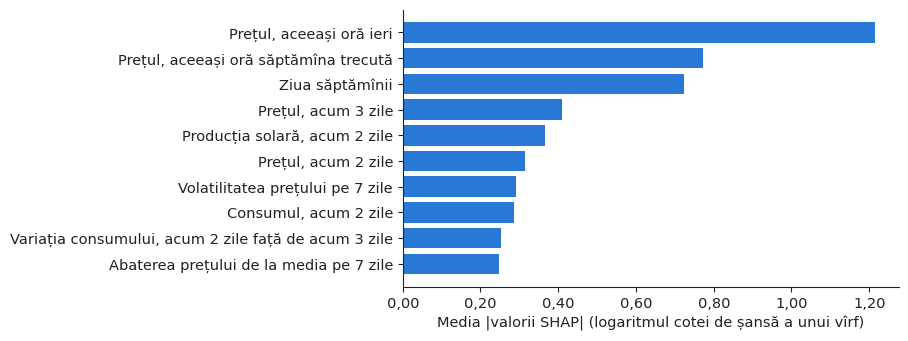

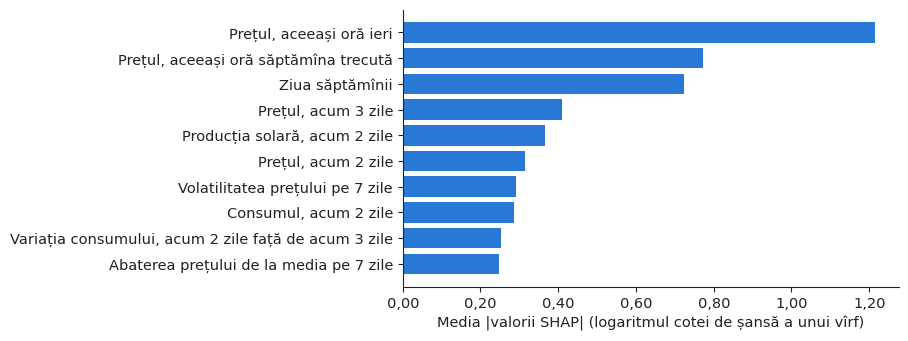

In [5]:
import shap
expl = shap.TreeExplainer(clf)
Xs = F[ite].sample(3000, random_state=0)
sv = expl.shap_values(Xs)
imp = pd.Series(np.abs(sv).mean(axis=0), index=F.columns).sort_values(ascending=False)
print(imp.head(10).round(3))
NM = {"price_lag24": ("Price, same hour yesterday", "Prețul, aceeași oră ieri"), "resid_load": ("Residual load, yesterday", "Consumul rezidual, ieri"),
      "solar": ("Solar output, 2 days ago", "Producția solară, acum 2 zile"), "hour": ("Hour of day", "Ora din zi"), "price_lag168": ("Price, same hour last week", "Prețul, aceeași oră săptămîna trecută"),
      "ren_share": ("Renewable share, 2 days ago", "Ponderea regenerabilelor, acum 2 zile"), "load": ("Load, 2 days ago", "Consumul, acum 2 zile"), "wind": ("Wind output, 2 days ago", "Producția eoliană, acum 2 zile"),
      "price_dev_7d": ("Price deviation from 7-day mean", "Abaterea prețului de la media pe 7 zile"), "price_vol_7d": ("7-day price volatility", "Volatilitatea prețului pe 7 zile"),
      "price_lag48": ("Price, 2 days ago", "Prețul, acum 2 zile"), "price_lag72": ("Price, 3 days ago", "Prețul, acum 3 zile"), "price_lag336": ("Price, 2 weeks ago", "Prețul, acum 2 săptămîni"),
      "month": ("Month", "Luna"), "dow": ("Day of week", "Ziua săptămînii"), "hydro_lag48": ("Hydro reservoir output, 2 days ago", "Producția hidro din lacuri, acum 2 zile"),
      "gas_lag48": ("Gas output, 2 days ago", "Producția pe gaze, acum 2 zile"), "import_lag48": ("Net imports, 2 days ago", "Importurile nete, acum 2 zile"),
      "balance_lag48": ("Hydro + gas minus load, 2 days ago", "Hidro + gaze minus consum, acum 2 zile"), "load_change_24h": ("Load change, 2 vs 3 days ago", "Variația consumului, acum 2 zile față de acum 3 zile"),
      "peak_evening": ("Evening peak (18-22 h)", "Vîrful de seară (orele 18–22)")}
def fig_shap(lang):
    fig, ax = plt.subplots(figsize=(6.4, 3.6))
    top = imp.head(10)[::-1]
    ax.barh([cu.T(lang, *NM.get(k, (k, k))) for k in top.index], top.values, color=cu.PAL["RO"])
    ax.set_xlabel(cu.T(lang, "Mean |SHAP value| (log-odds of a spike)", "Media |valorii SHAP| (logaritmul cotei de șansă a unui vîrf)"))
    cu.comma_axis(ax, lang, "x", 2)
    return fig
cu.save_both(fig_shap, "f2_shap_importance", headline=True)

## 3. Nivelul 2 - un scor de avertizare transparent, bazat pe praguri ale indicatorilor

In [6]:
# Each indicator raises a flag when it exceeds its threshold theta_m; theta_m maximises F1 on the TRAINING period (percentiles 50-95).
# Composite score W_t = sum_m w_m * flag_m,t with weights w_m proportional to each indicator's F1 (as the paper describes, Sec. 3);
# the alert threshold W* is chosen on the VALIDATION period.
IND = {"resid_load": +1, "price_lag24": +1, "price_dev_7d": +1, "price_vol_7d": +1, "load": +1, "ren_share": -1, "balance_lag48": -1}
th, f1w = {}, {}
for k, sgn in IND.items():
    v = sgn * F.loc[itr, k]
    cands = np.percentile(v, np.arange(50, 96, 1))
    f1s = [f1_score(yb[itr], v >= c) for c in cands]
    th[k] = cands[int(np.argmax(f1s))]; f1w[k] = max(f1s)
w = pd.Series(f1w) / sum(f1w.values())
flags = pd.DataFrame({k: (IND[k] * F[k] >= th[k]).astype(int) for k in IND})
W = flags @ w
gridW = np.linspace(0.05, 0.95, 37)
W_star = gridW[np.argmax([f1_score(yb[iva], W[iva] >= c) for c in gridW])]
ind_tab = pd.DataFrame({"threshold": {k: IND[k] * th[k] for k in IND}, "F1_train": f1w, "weight": w})
print(ind_tab.round(3)); print("alert threshold W* (validation): %.3f   (paper: 0.477)" % W_star)

               threshold  F1_train  weight
resid_load      6421.500     0.362   0.130
price_lag24      158.540     0.653   0.234
price_dev_7d      54.328     0.528   0.189
price_vol_7d      55.531     0.313   0.112
load            6973.202     0.365   0.131
ren_share          0.097     0.229   0.082
balance_lag48  -4892.250     0.345   0.123
alert threshold W* (validation): 0.500   (paper: 0.477)


In [7]:
res = pd.DataFrame({
    "XGBoost classifier": scores(yb[ite], prob[ite] > p_star, prob[ite]),
    "XGBoost price forecast > threshold": scores(yb[ite], pd.Series(reg.predict(F[ite]), index=F[ite].index) > thr, reg.predict(F[ite])),
    "Indicator warning score": scores(yb[ite], W[ite] >= W_star, W[ite]),
    "Naive: spike yesterday, same hour": scores(yb[ite], F.loc[ite, "price_lag24"] > thr, F.loc[ite, "price_lag24"]),
    "Perfect foresight: XGBoost, actual fundamentals": scores(yb[ite], prob_or[ite] > p_star_or, prob_or[ite]),
}).T
cu.show_table(res, best={"Precision": "max", "Recall": "max", "F1": "max", "Accuracy": "max", "AUC": "max"}, digits=3)

,Precision,Recall,F1,Accuracy,AUC
XGBoost classifier,0.823,0.517,0.635,0.868,0.946
XGBoost price forecast > threshold,0.808,0.723,0.763,0.901,0.950
Indicator warning score,0.682,0.443,0.537,0.831,0.861
"Naive: spike yesterday, same hour",0.770,0.765,0.767,0.897,0.931
"Perfect foresight: XGBoost, actual fundamentals",0.763,0.374,0.502,0.836,0.890


In [8]:
names = {"XGBoost classifier": ("XGBoost classifier (probability)", "Clasificator XGBoost (probabilitate)"),
         "XGBoost price forecast > threshold": ("XGBoost price forecast $>$ threshold", "Prognoza XGBoost a prețului $>$ prag"),
         "Indicator warning score": ("Indicator warning score", "Scorul de avertizare cu indicatori"),
         "Naive: spike yesterday, same hour": ("Naive: spike yesterday, same hour", "Naiv: vîrf ieri, la aceeași oră"),
         "Perfect foresight: XGBoost, actual fundamentals": ("XGBoost, actual fundamentals (perfect foresight)", "XGBoost, valori fundamentale efective (previziune perfectă)")}
t = res.copy(); t.index = [names[i] for i in t.index]
cu.write_table(t, "warning", header=[("Early-warning rule (test period)", "Regula de avertizare (perioada de test)"), ("Precision", "Precizia"), ("Recall", "Sensibilitatea"),
               ("F1", "F1"), ("Accuracy", "Acuratețea"), ("AUC", "AUC")], digits=3,
               best={"Precision": "max", "Recall": "max", "F1": "max", "Accuracy": "max", "AUC": "max"})
it = ind_tab.copy(); it.index = [NM.get(k, (k, k)) for k in it.index]
cu.write_table(it, "indicators", header=[("Indicator (flag if above; below for share/balance)", "Indicator (semnal la depășirea pragului; sub prag pentru pondere/sold)"),
               ("Threshold", "Pragul"), ("F1 (training)", "F1 (antrenare)"), ("Weight", "Ponderea")], digits={"threshold": 1, "F1_train": 3, "weight": 3},
               best={"F1_train": "max"})

## 4. De la o probabilitate la o decizie

Loss per missed spike-hour 150.8 EUR/MWh -> cost-loss threshold C/Loss = 0.199
value at C/Loss: 148.8 thousand EUR per MW of flexibility; at the F1-optimal threshold: 112.0


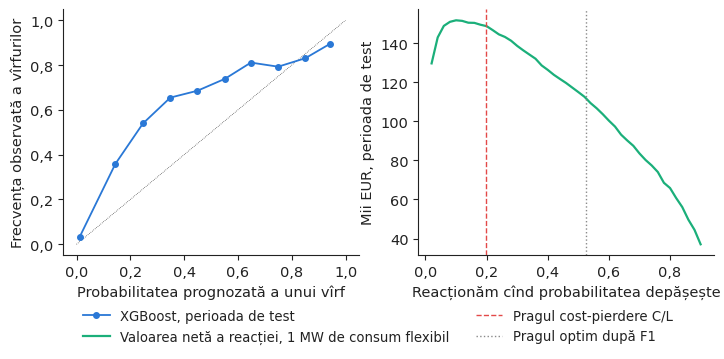

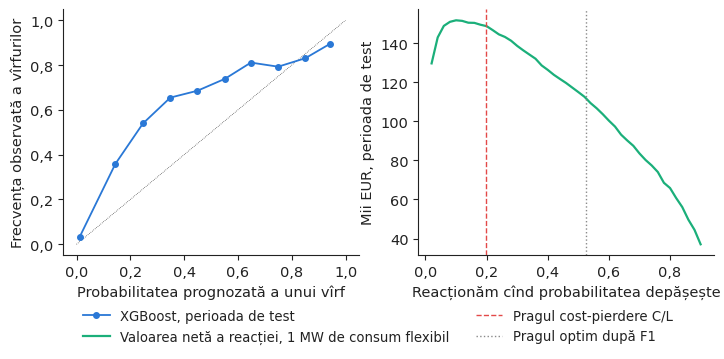

In [9]:
# Reliability: is a predicted 30 % spike probability followed by spikes 30 % of the time?
pt = prob[ite]; yt = yb[ite]
bins = np.linspace(0, 1, 11); cat = pd.cut(pt, bins, include_lowest=True)
rel = pd.DataFrame({"p": pt, "y": yt}).groupby(cat, observed=True).agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size"))
# Cost-loss rule: an action (e.g. shifting 1 MWh of flexible load out of the hour) costs C; if a spike occurs and we did not act we lose Loss.
# Acting is worth it when prob > C / Loss. Example: C = 30 EUR/MWh (lost production margin), Loss = mean spike price minus mean non-spike price.
C_ACT = 30.0
d_tr = df.loc[in_per(df.index, *TRAIN)]
LOSS = d_tr.query("spike == 1").price.mean() - d_tr.query("spike == 0").price.mean()
pc = C_ACT / LOSS
prices_te = yp[ite]
def value(cut):
    act = pt > cut
    return ((prices_te - prices_te.mean()) * act).sum() - C_ACT * act.sum()       # money saved by not buying in flagged hours, minus action cost
cuts = np.linspace(0.02, 0.9, 45)
vals = np.array([value(c) for c in cuts]) / 1000
print("Loss per missed spike-hour %.1f EUR/MWh -> cost-loss threshold C/Loss = %.3f" % (LOSS, pc))
print("value at C/Loss: %.1f thousand EUR per MW of flexibility; at the F1-optimal threshold: %.1f" % (value(pc) / 1000, value(p_star) / 1000))
def fig_decision(lang):
    fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.2))
    a = axes[0]
    a.plot([0, 1], [0, 1], color=cu.INK, lw=0.5, ls=":")
    a.plot(rel.p, rel.y, color=cu.PAL["RO"], marker="o", ms=4, label=cu.T(lang, "XGBoost, test period", "XGBoost, perioada de test"))
    a.set_xlabel(cu.T(lang, "Predicted spike probability", "Probabilitatea prognozată a unui vîrf")); a.set_ylabel(cu.T(lang, "Observed spike frequency", "Frecvența observată a vîrfurilor"))
    cu.comma_axis(a, lang, "x", 1); cu.comma_axis(a, lang, "y", 1)
    b = axes[1]
    b.plot(cuts, vals, color=cu.PAL["HU"], lw=1.6, label=cu.T(lang, "Net value of acting, 1 MW flexible load", "Valoarea netă a reacției, 1 MW de consum flexibil"))
    b.axvline(pc, color=cu.PAL["c8"], ls="--", lw=1, label=cu.T(lang, "Cost-loss threshold C/L", "Pragul cost-pierdere C/L"))
    b.axvline(p_star, color=cu.MUTED, ls=":", lw=1, label=cu.T(lang, "F1-optimal threshold", "Pragul optim după F1"))
    b.set_xlabel(cu.T(lang, "Act when probability exceeds", "Reacționăm cînd probabilitatea depășește")); b.set_ylabel(cu.T(lang, "Thousand EUR, test period", "Mii EUR, perioada de test"))
    cu.comma_axis(b, lang, "x", 1)
    cu.legend_bottom(fig, ncol=2)
    return fig
cu.save_both(fig_decision, "f4_decision")

peak 2026-06-30 21:00:00+03:00 price 954.6, predicted spike probability 0.900


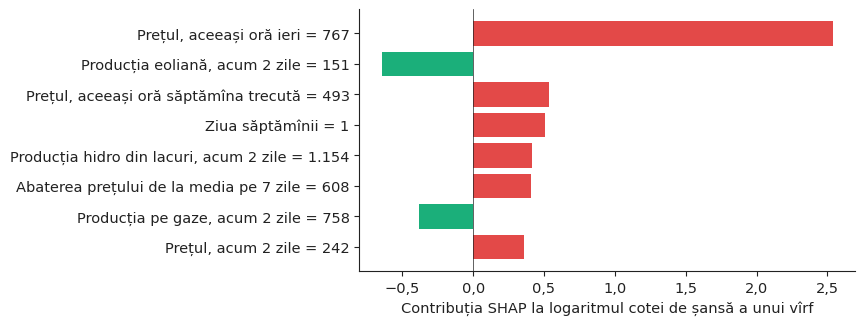

In [10]:
# Explain one alert: the largest spike of the test period (local explanation, like the paper's LIME case)
i_pk = yp[ite].idxmax()
sv_pk = pd.Series(expl.shap_values(F.loc[[i_pk]])[0], index=F.columns).sort_values(key=np.abs, ascending=False).head(8)
print("peak", i_pk, "price %.1f, predicted spike probability %.3f" % (yp[i_pk], prob[i_pk]))
def fig_local(lang):
    fig, ax = plt.subplots(figsize=(6.4, 3.4))
    s_ = sv_pk[::-1]
    ax.barh([cu.T(lang, *NM.get(k, (k, k))) + f" = {cu.fmt(F.loc[i_pk, k], 0, lang)}" for k in s_.index], s_.values,
            color=[cu.PAL["c8"] if v > 0 else cu.PAL["HU"] for v in s_.values])
    ax.axvline(0, color=cu.INK, lw=0.5)
    ax.set_xlabel(cu.T(lang, "SHAP contribution to the log-odds of a spike", "Contribuția SHAP la logaritmul cotei de șansă a unui vîrf"))
    cu.comma_axis(ax, lang, "x", 1)
    return fig
cu.save_both(fig_local, "f3_local_explanation")
r_ = res.loc["XGBoost classifier"]; r_w = res.loc["Indicator warning score"]
cu.write_numbers({
    "thr": thr, "spikeTrain": 100 * yb[itr].mean(), "spikeVal": 100 * yb[iva].mean(), "spikeTest": 100 * yb[ite].mean(), "nTest": int(ite.sum()),
    "pStar": p_star, "WStar": W_star, "top": NM.get(imp.index[0], (imp.index[0], imp.index[0])), "second": NM.get(imp.index[1], (imp.index[1], imp.index[1])),
    "third": NM.get(imp.index[2], (imp.index[2], imp.index[2])),
    "xPrec": r_.Precision, "xRec": r_.Recall, "xFone": r_.F1, "xAUC": r_.AUC, "wPrec": r_w.Precision, "wRec": r_w.Recall, "wFone": r_w.F1, "wAUC": r_w.AUC,
    "nFone": res.loc["Naive: spike yesterday, same hour", "F1"], "oFone": res.loc["Perfect foresight: XGBoost, actual fundamentals", "F1"],
    "oAUC": res.loc["Perfect foresight: XGBoost, actual fundamentals", "AUC"], "oRec": res.loc["Perfect foresight: XGBoost, actual fundamentals", "Recall"],
    "testStart": (f"{F.index[ite].min():%d %B %Y}", f"{F.index[ite].min():%d.%m.%Y}"), "testEnd": (f"{F.index[ite].max():%d %B %Y}", f"{F.index[ite].max():%d.%m.%Y}"), "rFone": res.loc["XGBoost price forecast > threshold", "F1"],
    "peakTime": (f"{i_pk:%d %B %Y, %H:00}", f"{i_pk:%d.%m.%Y, ora %H:00}"), "peakPrice": yp[i_pk], "peakProb": prob[i_pk],
    "loss": LOSS, "pc": pc, "valPc": value(pc) / 1000, "valPstar": value(p_star) / 1000, "bestCut": cuts[np.argmax(vals)], "bestVal": vals.max(),
}, digits={"thr": 2, "spikeTrain": 1, "spikeVal": 1, "spikeTest": 1, "pStar": 3, "WStar": 3, "xPrec": 3, "xRec": 3, "xFone": 3, "xAUC": 3,
           "wPrec": 3, "wRec": 3, "wFone": 3, "wAUC": 3, "nFone": 3, "oFone": 3, "oAUC": 3, "oRec": 3, "rFone": 3, "peakPrice": 1, "peakProb": 3, "loss": 1, "pc": 3,
           "valPc": 1, "valPstar": 1, "bestCut": 2, "bestVal": 1})

In [11]:
# slide-ready summary for the lecture box "Research from our group" (max 6 lines), both languages; every number comes from this notebook
for lang in ("en", "ro"):
    F = lambda v, nd=2: cu.fmt(float(v), nd, lang)
    t = lambda en, ro: ro if lang == "ro" else en
    j = 1 if lang == "ro" else 0
    top2 = [NM.get(k, (k, k))[j].lower() if lang == "ro" else NM.get(k, (k, k))[j] for k in imp.index[:2]]
    lines = [
        t("\\textbf{Explainable spike early warning} (Andrei, Pele, Cramer, Amza \\& Diaconu, 2026, PICBE): previous price and residual load drive spikes (SHAP, Table~5); warning system recall 0.722, F1 0.569 (Table~7).",
          "\\textbf{Avertizarea explicabilă privind vîrfurile de preț} (Andrei, Pele, Cramer, Amza și Diaconu, 2026, PICBE): prețul anterior și consumul rezidual determină vîrfurile (SHAP, Tabelul~5); sistemul are o sensibilitate de 0,722 și un scor F1 de 0,569 (Tabelul~7)."),
        t(f"Our replication (2023--Oct 2026, gate-closure information only): top drivers {top2[0]} and {top2[1]}; XGBoost AUC {F(r_.AUC)} (perfect foresight on fundamentals: {F(res.loc['Perfect foresight: XGBoost, actual fundamentals', 'AUC'])}).",
          f"Replicarea noastră (2023--oct.\\ 2026, numai cu informația de la închiderea porții): factorii principali sînt {top2[0]} și {top2[1]}; XGBoost obține un AUC de {F(r_.AUC)} (cu previziune perfectă a variabilelor fundamentale: {F(res.loc['Perfect foresight: XGBoost, actual fundamentals', 'AUC'])})."),
        t(f"But spikes became daily ({F(100 * yb[ite].mean(), 0)}\\,\\% of test hours vs {F(100 * yb[itr].mean(), 0)}\\,\\% in training): ``spike yesterday'' reaches F1 {F(res.loc['Naive: spike yesterday, same hour', 'F1'])} vs {F(r_.F1)} for XGBoost --- recalibrate thresholds.",
          f"Totuși, vîrfurile au devenit zilnice ({F(100 * yb[ite].mean(), 0)}\\,\\% din orele de test, față de {F(100 * yb[itr].mean(), 0)}\\,\\% în antrenare): regula „vîrf ieri” atinge F1 {F(res.loc['Naive: spike yesterday, same hour', 'F1'])}, față de {F(r_.F1)} pentru XGBoost --- recalibrați pragurile."),
        t("Decision: act when spike probability $> C/L$, from your own costs. See also foundation models for tail risk (Jheng et al., 2026, ECECSR).",
          "Decizia: reacționați atunci cînd probabilitatea unui vîrf depășește $C/L$, raport stabilit din propriile costuri. Vedeți și modelele fundamentale pentru riscul extrem (Jheng et al., 2026, ECECSR)."),
    ]
    with open(f"slide_summary_{lang}.tex", "w", encoding="utf-8") as fh:
        fh.write("% slide-ready summary for the lecture box 'Research from our group' (max 6 lines); generated by the notebook\n\\begin{itemize}\\setlength{\\itemsep}{2pt}\n")
        for l_ in lines:
            fh.write("  \\item " + l_ + "\n")
        fh.write("\\end{itemize}\n")
print(open("slide_summary_en.tex", encoding="utf-8").read())

% slide-ready summary for the lecture box 'Research from our group' (max 6 lines); generated by the notebook
\begin{itemize}\setlength{\itemsep}{2pt}
  \item \textbf{Explainable spike early warning} (Andrei, Pele, Cramer, Amza \& Diaconu, 2026, PICBE): previous price and residual load drive spikes (SHAP, Table~5); warning system recall 0.722, F1 0.569 (Table~7).
  \item Our replication (2023--Oct 2026, gate-closure information only): top drivers Price, same hour yesterday and Price, same hour last week; XGBoost AUC 0.95 (perfect foresight on fundamentals: 0.89).
  \item But spikes became daily (22\,\% of test hours vs 10\,\% in training): ``spike yesterday'' reaches F1 0.77 vs 0.63 for XGBoost --- recalibrate thresholds.
  \item Decision: act when spike probability $> C/L$, from your own costs. See also foundation models for tail risk (Jheng et al., 2026, ECECSR).
\end{itemize}



## Exerciții suplimentare
1. Reestimați modelele numai pe perioada din lucrare (martie-septembrie 2024, împărțire 80/10/10). Obțineți aceeași ordine a factorilor ca în lucrare (prețul anterior, consumul rezidual)?
2. Modificați costul reacției C de la 30 la 100 EUR/MWh. Cum se deplasează pragul optim de alertă și de ce?
3. Înlocuiți clasificatorul cu modelul probabilistic Random Forest din studiul de caz 6 și estimați P(preț > prag) din ponderile acestuia. Este mai bine calibrat?